### Pivot Table
The Pivot table takes simple column-wise data as input, and groups the entries into a two-dimensional table that provides a multidimensional summarization of the data.

In [4]:
import numpy as np
import pandas as pd

In [7]:
df = pd.DataFrame(
    {
        'Order_ID': [101,102,103,104,105,106,107,108,109,110,111,112],
        'Date':['2026-01-01', '2026-01-03', '2026-01-05', '2026-01-07', '2026-01-10', '2026-01-12', '2026-01-15', '2026-01-18', '2026-01-20', '2026-01-22', '2026-01-25', '2026-01-28'],
        'Region':['North', 'South', 'East','West','North', 'South', 'North', 'East', 'West', 'South', 'East', 'West'],
        'Category': ['Electronics', 'Furniture', 'Electronics', 'Furniture', 'Electronics', 'Electronics', 'Furniture', 'Furniture','Electronics','Electronics','Electronics','Furniture'],
        'Product': ['Laptop','Chair','Mobile','Table','Mobile','Laptop','Chair','Table','Headphone','Mobile','Headphone','Chair'],
        'Units_Sold':[2,10,5,2,4,1,6,1,15,3,8,4],
        'Revenue':[110000,15000,75000,24000,60000,55000,9000,12000,30000,45000,16000,6000]
    }
)

df

,Order_ID,Date,Region,Category,Product,Units_Sold,Revenue
0,101,2026-01-01,North,Electronics,Laptop,2,110000
1,102,2026-01-03,South,Furniture,Chair,10,15000
2,103,2026-01-05,East,Electronics,Mobile,5,75000
3,104,2026-01-07,West,Furniture,Table,2,24000
4,105,2026-01-10,North,Electronics,Mobile,4,60000
5,106,2026-01-12,South,Electronics,Laptop,1,55000
6,107,2026-01-15,North,Furniture,Chair,6,9000
7,108,2026-01-18,East,Furniture,Table,1,12000
8,109,2026-01-20,West,Electronics,Headphone,15,30000
9,110,2026-01-22,South,Electronics,Mobile,3,45000


In [9]:
df.pivot_table(index='Region',values='Revenue',aggfunc='sum')

,Revenue
Region,
East,103000
North,179000
South,115000
West,60000


#### Basic Level Questions

In [22]:
# 1. Total Revenue by Region:
category = df.pivot_table(index='Region', columns='Category', values='Revenue', aggfunc='sum')
category['Total Revenue'] = category.sum(axis=1)
category

Category,Electronics,Furniture,Total Revenue
Region,,,
East,91000,12000,103000
North,170000,9000,179000
South,100000,15000,115000
West,30000,30000,60000


In [26]:
# Total units sold by product
df.groupby('Product')[['Units_Sold']].sum()

,Units_Sold
Product,
Chair,20
Headphone,23
Laptop,3
Mobile,12
Table,3


In [25]:
df.pivot_table(index='Product',values='Units_Sold',aggfunc='sum')

,Units_Sold
Product,
Chair,20
Headphone,23
Laptop,3
Mobile,12
Table,3


In [28]:
# Average Revenue per Category
df.pivot_table(index='Category',values='Revenue',aggfunc ='mean').round(2)

,Revenue
Category,
Electronics,55857.14
Furniture,13200.00


In [30]:
# Transaction count by region
df.pivot_table(index='Region', values='Product',aggfunc='count')

,Product
Region,
East,3
North,3
South,3
West,3


#### Intermediate Level Questions

In [31]:
# Region vs Category Cross-Table:
df.pivot_table(index='Region', columns='Category', values='Revenue',aggfunc='sum')

Category,Electronics,Furniture
Region,,
East,91000,12000
North,170000,9000
South,100000,15000
West,30000,30000


In [41]:
# Category and product hierarchy:
df.pivot_table(index=['Category','Product'] ,values=['Units_Sold','Revenue'],aggfunc={'Units_Sold':'sum','Revenue':'sum'}, fill_value=0)

Revenue  Units_Sold
Category    Product                       
Electronics Headphone    46000          23
            Laptop      165000           3
            Mobile      180000          12
Furniture   Chair        30000          20
            Table        36000           3

In [43]:
# multiple aggregations(sum & average)

df.pivot_table(index=['Category','Product'],values=['Units_Sold','Revenue'], aggfunc={'Units_Sold':['sum','mean'],'Revenue':['sum','mean']})

Revenue         Units_Sold    
                          mean     sum       mean sum
Category    Product                                  
Electronics Headphone  23000.0   46000  11.500000  23
            Laptop     82500.0  165000   1.500000   3
            Mobile     60000.0  180000   4.000000  12
Furniture   Chair      10000.0   30000   6.666667  20
            Table      18000.0   36000   1.500000   3

####  Advanced level Questions

In [47]:
# Grand Totals(margins)
a = df.pivot_table(index='Region',columns='Category', values='Units_Sold', aggfunc='sum',fill_value=0)
a['Total Quantity'] = a.sum(axis=1)
a

Category,Electronics,Furniture,Total Quantity
Region,,,
East,13,1,14
North,6,6,12
South,4,10,14
West,15,6,21


In [49]:
df.pivot_table(index='Region',columns='Category', values='Units_Sold', aggfunc='sum',fill_value=0, margins=True, margins_name='Total Quantity')

Category,Electronics,Furniture,Total Quantity
Region,,,
East,13,1,14
North,6,6,12
South,4,10,14
West,15,6,21
Total Quantity,38,23,61


In [50]:
# Max and Min Revenue per product

df.pivot_table(index='Product', values='Revenue', aggfunc=['min','max'])

,min,max
,Revenue,Revenue
Product,,
Chair,6000,15000
Headphone,16000,30000
Laptop,55000,110000
Mobile,45000,75000
Table,12000,24000


In [54]:
# Filtered pivot table(only Electronics)
df = df[df['Category'] == 'Electronics']
df.pivot_table(index='Region',values='Revenue', aggfunc='sum')

,Revenue
Region,
East,91000
North,170000
South,100000
West,30000


In [66]:
df = pd.read_csv('expense_data .csv')
df['Date'] = pd.to_datetime(df['Date'])
df['month'] = df['Date'].dt.month_name()

<Axes: xlabel='month,Category'>

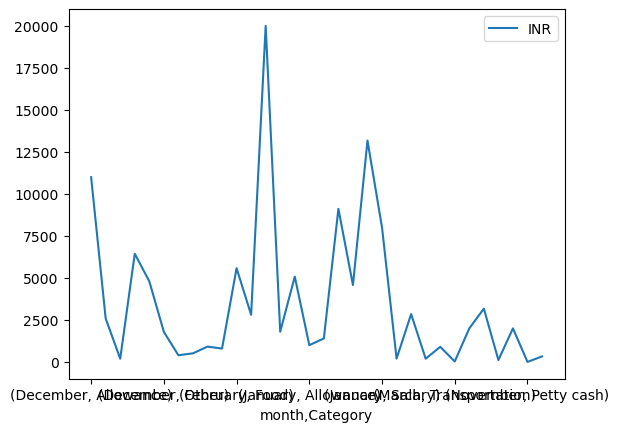

In [73]:
df.groupby(['month','Category'])[['INR']].sum().plot()

<Axes: xlabel='month'>

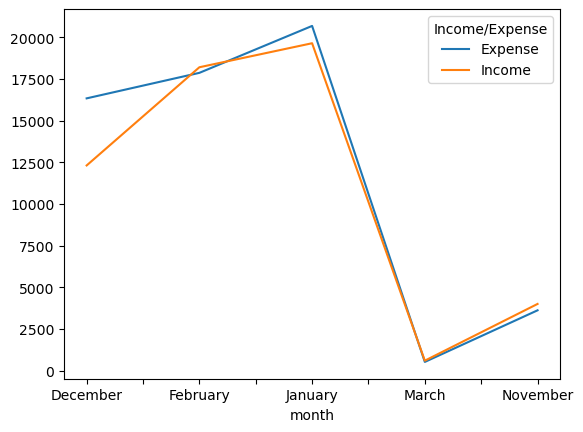

In [85]:
df.pivot_table(index='month', columns='Income/Expense', values='INR', aggfunc='sum', fill_value=0).plot()

<Axes: xlabel='month'>

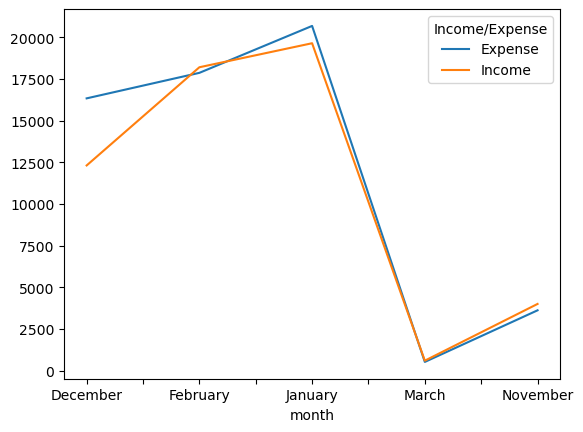

In [86]:
df.groupby(['month','Income/Expense'])['INR'].sum().unstack().plot()

### Vectorized String Operations

In [97]:
s = ['cat','mat','rat','call','cow', None]
a = []
for word in s:
     if word.startswith('c'):
         a.append(word)
a

AttributeError: 'NoneType' object has no attribute 'startswith'

In [112]:
# How pandas solves this issue?
s = pd.Series(['cat','mat','rat','call','cow', None])
# string accessor
clean_s = s.dropna()
clean_s[clean_s.str.startswith('c')]

0     cat
3    call
4     cow
dtype: object

In [114]:
df = pd.read_csv('titanic.csv')
df.head(2)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C


In [115]:
df.Name

0                                Braund, Mr. Owen Harris
1      Cumings, Mrs. John Bradley (Florence Briggs Th...
2                                 Heikkinen, Miss. Laina
3           Futrelle, Mrs. Jacques Heath (Lily May Peel)
4                               Allen, Mr. William Henry
                             ...                        
886                                Montvila, Rev. Juozas
887                         Graham, Miss. Margaret Edith
888             Johnston, Miss. Catherine Helen "Carrie"
889                                Behr, Mr. Karl Howell
890                                  Dooley, Mr. Patrick
Name: Name, Length: 891, dtype: object

In [119]:
df.Name.str.lower()
df['Name'].str.upper()
df['Name'].str.capitalize()
df['Name'].str.title()

0                                Braund, Mr. Owen Harris
1      Cumings, Mrs. John Bradley (Florence Briggs Th...
2                                 Heikkinen, Miss. Laina
3           Futrelle, Mrs. Jacques Heath (Lily May Peel)
4                               Allen, Mr. William Henry
                             ...                        
886                                Montvila, Rev. Juozas
887                         Graham, Miss. Margaret Edith
888             Johnston, Miss. Catherine Helen "Carrie"
889                                Behr, Mr. Karl Howell
890                                  Dooley, Mr. Patrick
Name: Name, Length: 891, dtype: object

In [143]:
df['Name'][df['Name'].str.len().sort_values(ascending=False).reset_index().iloc[0,0]]

'Penasco y Castellana, Mrs. Victor de Satode (Maria Josefa Perez de Soto y Vallejo)'

In [151]:
# split
df['lastname'] = df['Name'].str.split(',').str.get(0)
df

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,lastname
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,Braund
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,Cumings
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,Heikkinen
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,Futrelle
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,Allen
...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S,Montvila
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S,Graham
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S,Johnston
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C,Behr


In [185]:
df[['title','firstname']] = df['Name'].str.split(',').str.get(1).str.strip().str.split(' ', n=1, expand=True)
df.head(2)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,lastname,title,firstname
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,Braund,Mr.,Owen Harris
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,Cumings,Mrs.,John Bradley (Florence Briggs Thayer)


In [187]:
df['title'].value_counts()

title
Mr.          517
Miss.        182
Mrs.         125
Master.       40
Dr.            7
Rev.           6
Mlle.          2
Major.         2
Col.           2
the            1
Capt.          1
Ms.            1
Sir.           1
Lady.          1
Mme.           1
Don.           1
Jonkheer.      1
Name: count, dtype: int64

In [204]:
# replace

df['title'] = df['title'].str.replace('Ms.','Miss.')
df['title'] = df['title'].str.replace('Mlle.','Miss.')

In [205]:
df['title'].value_counts()

title
Mr.          517
Miss.        185
Mrs.         125
Master.       40
Dr.            7
Rev.           6
Major.         2
Col.           2
Don.           1
Mme.           1
Lady.          1
Sir.           1
Capt.          1
the            1
Jonkheer.      1
Name: count, dtype: int64

In [209]:
# filtering
# startswith/endswith
df['firstname'][df['firstname'].str.startswith('A')]

13            Anders Johan
22            Anna "Annie"
35         Alexander Oskar
38           Augusta Maria
61                  Amelie
              ...         
842                Augusta
845                Anthony
866               Asuncion
875    Adele Kiamie "Jane"
876          Alfred Ossian
Name: firstname, Length: 95, dtype: object

In [210]:
df['firstname'][df['firstname'].str.endswith('A')]

64     Albert A
303      Nora A
Name: firstname, dtype: object

In [213]:
# isdigit/isalpha....
df[df['firstname'].str.isdigit()]

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,lastname,title,firstname


In [215]:
df[df['firstname'].str.contains('john',case=False)]

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,lastname,title,firstname
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,Cumings,Mrs.,John Bradley (Florence Briggs Thayer)
41,42,0,2,"Turpin, Mrs. William John Robert (Dorothy Ann ...",female,27.0,1,0,11668,21.0000,NaN,S,Turpin,Mrs.,William John Robert (Dorothy Ann Wonnacott)
45,46,0,3,"Rogers, Mr. William John",male,NaN,0,0,S.C./A.4. 23567,8.0500,NaN,S,Rogers,Mr.,William John
98,99,1,2,"Doling, Mrs. John T (Ada Julia Bone)",female,34.0,0,1,231919,23.0000,NaN,S,Doling,Mrs.,John T (Ada Julia Bone)
112,113,0,3,"Barton, Mr. David John",male,22.0,0,0,324669,8.0500,NaN,S,Barton,Mr.,David John
117,118,0,2,"Turpin, Mr. William John Robert",male,29.0,1,0,11668,21.0000,NaN,S,Turpin,Mr.,William John Robert
160,161,0,3,"Cribb, Mr. John Hatfield",male,44.0,0,1,371362,16.1000,NaN,S,Cribb,Mr.,John Hatfield
162,163,0,3,"Bengtsson, Mr. John Viktor",male,26.0,0,0,347068,7.7750,NaN,S,Bengtsson,Mr.,John Viktor
165,166,1,3,"Goldsmith, Master. Frank John William ""Frankie""",male,9.0,0,2,363291,20.5250,NaN,S,Goldsmith,Master.,"Frank John William ""Frankie"""
168,169,0,1,"Baumann, Mr. John D",male,NaN,0,0,PC 17318,25.9250,NaN,S,Baumann,Mr.,John D


In [218]:
# find last names with start and end char vowel

df[df['lastname'].str.contains('^[aeiouAEIOU].+[aeiouAEIOU]$')]

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,lastname,title,firstname
30,31,0,1,"Uruchurtu, Don. Manuel E",male,40.0,0,0,PC 17601,27.7208,NaN,C,Uruchurtu,Don.,Manuel E
49,50,0,3,"Arnold-Franchi, Mrs. Josef (Josefine Franchi)",female,18.0,1,0,349237,17.8000,NaN,S,Arnold-Franchi,Mrs.,Josef (Josefine Franchi)
207,208,1,3,"Albimona, Mr. Nassef Cassem",male,26.0,0,0,2699,18.7875,NaN,C,Albimona,Mr.,Nassef Cassem
210,211,0,3,"Ali, Mr. Ahmed",male,24.0,0,0,SOTON/O.Q. 3101311,7.0500,NaN,S,Ali,Mr.,Ahmed
353,354,0,3,"Arnold-Franchi, Mr. Josef",male,25.0,1,0,349237,17.8000,NaN,S,Arnold-Franchi,Mr.,Josef
493,494,0,1,"Artagaveytia, Mr. Ramon",male,71.0,0,0,PC 17609,49.5042,NaN,C,Artagaveytia,Mr.,Ramon
518,519,1,2,"Angle, Mrs. William A (Florence ""Mary"" Agnes H...",female,36.0,1,0,226875,26.0000,NaN,S,Angle,Mrs.,"William A (Florence ""Mary"" Agnes Hughes)"
784,785,0,3,"Ali, Mr. William",male,25.0,0,0,SOTON/O.Q. 3101312,7.0500,NaN,S,Ali,Mr.,William
840,841,0,3,"Alhomaki, Mr. Ilmari Rudolf",male,20.0,0,0,SOTON/O2 3101287,7.9250,NaN,S,Alhomaki,Mr.,Ilmari Rudolf


In [219]:
df[df['lastname'].str.contains('^[^aeiouAEIOU].+[^aeiouAEIOU]$')]

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,lastname,title,firstname
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,Braund,Mr.,Owen Harris
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,Cumings,Mrs.,John Bradley (Florence Briggs Thayer)
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,Heikkinen,Miss.,Laina
5,6,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q,Moran,Mr.,James
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S,McCarthy,Mr.,Timothy J
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
884,885,0,3,"Sutehall, Mr. Henry Jr",male,25.0,0,0,SOTON/OQ 392076,7.0500,NaN,S,Sutehall,Mr.,Henry Jr
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S,Graham,Miss.,Margaret Edith
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S,Johnston,Miss.,"Catherine Helen ""Carrie"""
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C,Behr,Mr.,Karl Howell


In [225]:
# slicing
df['Name'].str[:4]

0      Brau
1      Cumi
2      Heik
3      Futr
4      Alle
       ... 
886    Mont
887    Grah
888    John
889    Behr
890    Dool
Name: Name, Length: 891, dtype: object

### Timestamp Object
Time stamps particular moments in time(eg oct24th,2022 at 7:00pm)

### Creating Timestamp objects

In [247]:
pd.Timestamp('2026/10/2')
pd.Timestamp('2026-10-2')
pd.Timestamp('2026, 10, 2')
pd.Timestamp('2nd oct 2026')

Timestamp('2026-10-02 00:00:00')

In [249]:
# providing time also
pd.Timestamp('2nd Oct 2026 8:8pm' )

Timestamp('2026-10-02 20:08:00')

In [250]:
# using datetime.datetime object
import datetime as dt

dt.datetime(2023,1,5,9,21,56)

datetime.datetime(2023, 1, 5, 9, 21, 56)

In [252]:
x = pd.Timestamp(dt.datetime(2023,1,5,9,21,56))
x

Timestamp('2023-01-05 09:21:56')

In [259]:
# fetching attributes
x.month
x.year
x.day
x.hour
x.minute
x.second

56

In [263]:
a = pd.Timestamp('2nd Oct 2026 8:8pm' )
a.year
a.month

10

### Why seperate objects to handle date and time when python already has datetime functionality?



1. syntex wise datetime is very convenient
2. But the performance takes a hit while working with huge data. List vs Numpy Array
3. The weakness of Python's datetime format inspired the NumPy team to add a set of native time series data type to NumPy.
4. The datetime64 type encodes dates as 64-bit integers, and thus allows arrays of dates to be represented very compactly.

In [264]:
import numpy as np
date = np.array('2025-07-04', dtype=np.datetime64)
date

array('2025-07-04', dtype='datetime64[D]')

In [265]:
date + np.arange(12)

array(['2025-07-04', '2025-07-05', '2025-07-06', '2025-07-07',
       '2025-07-08', '2025-07-09', '2025-07-10', '2025-07-11',
       '2025-07-12', '2025-07-13', '2025-07-14', '2025-07-15'],
      dtype='datetime64[D]')

5. Because of the uniform type in NumPy datetime64 arrays, this type of operation can be accomplished much more quickly than if we were working directly with Python's datetime objects, especially as arrays get large
6. Pandas Timestamp object combines the ease-of-use of python datetime with the efficient storage and vectorized interface of numpy.datetime64
7. From a group of these Timestamp objects, Pandas can caonstruct a Datetimeindex that can be used to index data in a Series of DataFrame

### Datetimeindex Object

A collection of pandas timestamp

In [337]:
# from strings
a = pd.DatetimeIndex(['2026/10/1','2026/10/2','2026/10/3'])
a

DatetimeIndex(['2026-10-01', '2026-10-02', '2026-10-03'], dtype='datetime64[ns]', freq=None)

In [338]:
a[0]

Timestamp('2026-10-01 00:00:00')

In [339]:
# using python datetime object
pd.DatetimeIndex([dt.datetime(2023,1,1), dt.datetime(2023,1,2), dt.datetime(2023,1,3)])

DatetimeIndex(['2023-01-01', '2023-01-02', '2023-01-03'], dtype='datetime64[ns]', freq=None)

In [342]:
# using pd.timestamp
dt_index = pd.DatetimeIndex([pd.Timestamp(2023,1,1), pd.Timestamp(2023,1,2), pd.Timestamp(2023,1,3)])
dt_index

DatetimeIndex(['2023-01-01', '2023-01-02', '2023-01-03'], dtype='datetime64[ns]', freq=None)

In [343]:
# using datetimeindex as series index
pd.Series([1,2,3], index=dt_index)

2023-01-01    1
2023-01-02    2
2023-01-03    3
dtype: int64

### date_range function

In [346]:
# generate daily dates in a given range
pd.date_range(start='2026/10/1', end='2026/10/31', freq='D')

DatetimeIndex(['2026-10-01', '2026-10-02', '2026-10-03', '2026-10-04',
               '2026-10-05', '2026-10-06', '2026-10-07', '2026-10-08',
               '2026-10-09', '2026-10-10', '2026-10-11', '2026-10-12',
               '2026-10-13', '2026-10-14', '2026-10-15', '2026-10-16',
               '2026-10-17', '2026-10-18', '2026-10-19', '2026-10-20',
               '2026-10-21', '2026-10-22', '2026-10-23', '2026-10-24',
               '2026-10-25', '2026-10-26', '2026-10-27', '2026-10-28',
               '2026-10-29', '2026-10-30', '2026-10-31'],
              dtype='datetime64[ns]', freq='D')

In [347]:
# alternate days in a given range
pd.date_range(start='2026/10/1', end='2026/10/31', freq='2D')

DatetimeIndex(['2026-10-01', '2026-10-03', '2026-10-05', '2026-10-07',
               '2026-10-09', '2026-10-11', '2026-10-13', '2026-10-15',
               '2026-10-17', '2026-10-19', '2026-10-21', '2026-10-23',
               '2026-10-25', '2026-10-27', '2026-10-29', '2026-10-31'],
              dtype='datetime64[ns]', freq='2D')

In [349]:
# B -> business days
pd.date_range(start='2026/10/1', end='2026/10/31', freq='B')

DatetimeIndex(['2026-10-01', '2026-10-02', '2026-10-05', '2026-10-06',
               '2026-10-07', '2026-10-08', '2026-10-09', '2026-10-12',
               '2026-10-13', '2026-10-14', '2026-10-15', '2026-10-16',
               '2026-10-19', '2026-10-20', '2026-10-21', '2026-10-22',
               '2026-10-23', '2026-10-26', '2026-10-27', '2026-10-28',
               '2026-10-29', '2026-10-30'],
              dtype='datetime64[ns]', freq='B')

In [351]:
# W -> one week per day
pd.date_range(start='2026/10/1', end='2026/10/31', freq='W-mon')

DatetimeIndex(['2026-10-05', '2026-10-12', '2026-10-19', '2026-10-26'], dtype='datetime64[ns]', freq='W-MON')

In [354]:
# h -> hourly data(factor)
pd.date_range(start='2026/10/1', end='2026/10/31', freq='6h')

DatetimeIndex(['2026-10-01 00:00:00', '2026-10-01 06:00:00',
               '2026-10-01 12:00:00', '2026-10-01 18:00:00',
               '2026-10-02 00:00:00', '2026-10-02 06:00:00',
               '2026-10-02 12:00:00', '2026-10-02 18:00:00',
               '2026-10-03 00:00:00', '2026-10-03 06:00:00',
               ...
               '2026-10-28 18:00:00', '2026-10-29 00:00:00',
               '2026-10-29 06:00:00', '2026-10-29 12:00:00',
               '2026-10-29 18:00:00', '2026-10-30 00:00:00',
               '2026-10-30 06:00:00', '2026-10-30 12:00:00',
               '2026-10-30 18:00:00', '2026-10-31 00:00:00'],
              dtype='datetime64[ns]', length=121, freq='6h')

In [358]:
# ME -> Month end
pd.date_range(start='2026/10/2', end='2026/10/31', freq='ME')

DatetimeIndex(['2026-10-31'], dtype='datetime64[ns]', freq='ME')

In [360]:
# MS -> Month Start

pd.date_range(start='2026/10/1', end='2026/10/31', freq='MS')

DatetimeIndex(['2026-10-01'], dtype='datetime64[ns]', freq='MS')

In [364]:
# using periods(number of results)
pd.date_range(start='2026/10/1', periods=25, freq='B')

DatetimeIndex(['2026-10-01', '2026-10-02', '2026-10-05', '2026-10-06',
               '2026-10-07', '2026-10-08', '2026-10-09', '2026-10-12',
               '2026-10-13', '2026-10-14', '2026-10-15', '2026-10-16',
               '2026-10-19', '2026-10-20', '2026-10-21', '2026-10-22',
               '2026-10-23', '2026-10-26', '2026-10-27', '2026-10-28',
               '2026-10-29', '2026-10-30', '2026-11-02', '2026-11-03',
               '2026-11-04'],
              dtype='datetime64[ns]', freq='B')

### to_datetime function
converts an existing objects to pandas timestamp/datetimeindex object

In [373]:
#  simple series example
s = pd.Series(['2026/1/1','2026/1/2','2026/1/3'])
pd.to_datetime(s).dt.year
pd.to_datetime(s).dt.month
pd.to_datetime(s).dt.day
pd.to_datetime(s).dt.month_name()
pd.to_datetime(s).dt.day_name()

0    Thursday
1      Friday
2    Saturday
dtype: object

In [380]:
# with errors
s = pd.Series(['2026/1/1','2026/1/2','2026/130/3'])
pd.to_datetime(s, errors='coerce').dt.year

0    2026.0
1    2026.0
2       NaN
dtype: float64

In [382]:
df = pd.read_csv('expense_data .csv')
df.head()

,Date,Account,Category,Subcategory,Note,INR,Income/Expense,Note.1,Amount,Currency,Account.1
0,3/2/2022 10:11,CUB - online payment,Food,NaN,Brownie,50.0,Expense,NaN,50.0,INR,50.0
1,3/2/2022 10:11,CUB - online payment,Other,NaN,To lended people,300.0,Expense,NaN,300.0,INR,300.0
2,3/1/2022 19:50,CUB - online payment,Food,NaN,Dinner,78.0,Expense,NaN,78.0,INR,78.0
3,3/1/2022 18:56,CUB - online payment,Transportation,NaN,Metro,30.0,Expense,NaN,30.0,INR,30.0
4,3/1/2022 18:22,CUB - online payment,Food,NaN,Snacks,67.0,Expense,NaN,67.0,INR,67.0


In [385]:
df['Date'] = pd.to_datetime(df['Date'])

In [386]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 277 entries, 0 to 276
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Date            277 non-null    datetime64[ns]
 1   Account         277 non-null    object        
 2   Category        277 non-null    object        
 3   Subcategory     0 non-null      float64       
 4   Note            273 non-null    object        
 5   INR             277 non-null    float64       
 6   Income/Expense  277 non-null    object        
 7   Note.1          0 non-null      float64       
 8   Amount          277 non-null    float64       
 9   Currency        277 non-null    object        
 10  Account.1       277 non-null    float64       
dtypes: datetime64[ns](1), float64(5), object(5)
memory usage: 23.9+ KB


### dt accessor
Accessor object for datetimelike properties of the Series values.

In [393]:
df['Date'].dt.year
df['Date'].dt.month
df['Date'].dt.month_name()
df['Date'].dt.day_name()
df['Date'].dt.is_month_end

0      False
1      False
2      False
3      False
4      False
       ...  
272    False
273    False
274    False
275    False
276    False
Name: Date, Length: 277, dtype: bool

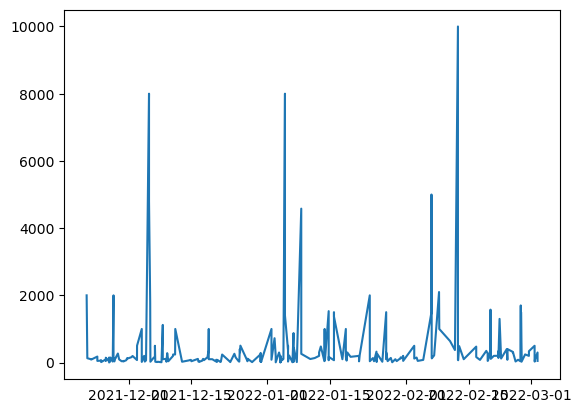

In [396]:
# plot graph
import matplotlib.pyplot as plt
plt.plot(df['Date'], df['INR'])

In [401]:
# day name wise bar chart/month wise bar chart
df['day_name'] = df['Date'].dt.day_name()
df.head()

,Date,Account,Category,Subcategory,Note,INR,Income/Expense,Note.1,Amount,Currency,Account.1,day_name
0,2022-03-02 10:11:00,CUB - online payment,Food,NaN,Brownie,50.0,Expense,NaN,50.0,INR,50.0,Wednesday
1,2022-03-02 10:11:00,CUB - online payment,Other,NaN,To lended people,300.0,Expense,NaN,300.0,INR,300.0,Wednesday
2,2022-03-01 19:50:00,CUB - online payment,Food,NaN,Dinner,78.0,Expense,NaN,78.0,INR,78.0,Tuesday
3,2022-03-01 18:56:00,CUB - online payment,Transportation,NaN,Metro,30.0,Expense,NaN,30.0,INR,30.0,Tuesday
4,2022-03-01 18:22:00,CUB - online payment,Food,NaN,Snacks,67.0,Expense,NaN,67.0,INR,67.0,Tuesday


<Axes: xlabel='day_name'>

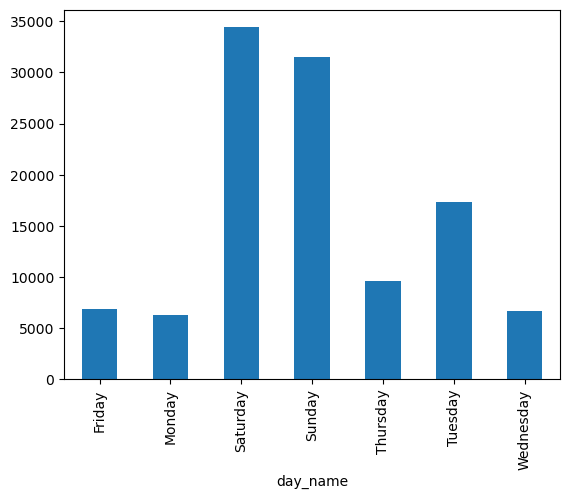

In [405]:
df.groupby('day_name')['Amount'].sum().plot(kind='bar')

In [407]:
df['month_name'] = df['Date'].dt.month_name()
df.head()

,Date,Account,Category,Subcategory,Note,INR,Income/Expense,Note.1,Amount,Currency,Account.1,day_name,month_name
0,2022-03-02 10:11:00,CUB - online payment,Food,NaN,Brownie,50.0,Expense,NaN,50.0,INR,50.0,Wednesday,March
1,2022-03-02 10:11:00,CUB - online payment,Other,NaN,To lended people,300.0,Expense,NaN,300.0,INR,300.0,Wednesday,March
2,2022-03-01 19:50:00,CUB - online payment,Food,NaN,Dinner,78.0,Expense,NaN,78.0,INR,78.0,Tuesday,March
3,2022-03-01 18:56:00,CUB - online payment,Transportation,NaN,Metro,30.0,Expense,NaN,30.0,INR,30.0,Tuesday,March
4,2022-03-01 18:22:00,CUB - online payment,Food,NaN,Snacks,67.0,Expense,NaN,67.0,INR,67.0,Tuesday,March


<Axes: xlabel='month_name'>

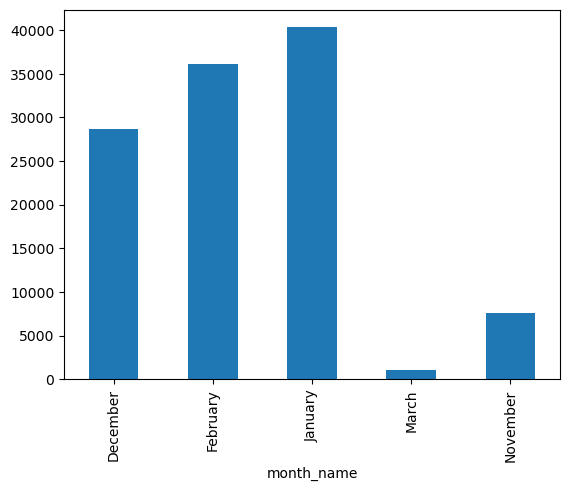

In [409]:
df.groupby('month_name')['INR'].sum().plot(kind='bar')